# V Rising — Public Steam Review Analysis

A small, honest look at public Steam reviews for *V Rising* (Steam app id
`1604030`), built as a portfolio piece.

**Data source:** Steam's own storefront review data, fetched with
`scripts/fetch_reviews.py` (see that file for a note on the endpoint).
English-language reviews only. No usernames, SteamIDs, or other author
identifiers are collected or stored — only review text, recommended
yes/no, timestamp, playtime at time of review, and vote counts.

**Not affiliated with or endorsed by Stunlock Studios.** This is an
independent analysis of public data, built to demonstrate an analysis
workflow, not an official or authoritative account of the game's
reception.


In [1]:
import sys
sys.path.append("../scripts")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from analysis import (
    MAJOR_UPDATES,
    load_reviews,
    weekly_volume_and_positivity,
    playtime_by_recommendation,
    topic_model_negative_reviews,
)

pd.set_option("display.max_colwidth", 120)
DATA_PATH = "../data/reviews_raw.jsonl"


## Load data

In [2]:
df = load_reviews(DATA_PATH)
print(f"{len(df):,} reviews loaded")
print(f"Date range: {df['created_at'].min().date()} to {df['created_at'].max().date()}")
print(f"Overall % positive: {df['recommended'].mean() * 100:.1f}%")
df.head(3)


24,835 reviews loaded
Date range: 2024-05-14 to 2026-11-10
Overall % positive: 88.5%


,review_text,recommended,timestamp_created,playtime_at_review_minutes,votes_up,votes_funny,created_at,playtime_at_review_hours
0,I have played through this game on Brutal difficulty close to a dozen times. I come back every 6 months to play it a...,True,2026-11-10 12:48:54,19613,0,0,2026-11-10 12:48:54+00:00,326.883333
1,So far... it is perfect... It is to die for... I feel alive again!,True,2026-11-10 07:18:42,176,0,0,2026-11-10 07:18:42+00:00,2.933333
2,"Very fun, will recommend",True,2026-11-10 01:18:30,3795,0,0,2026-11-10 01:18:30+00:00,63.250000


## 1. Review volume and % positive per week

Dashed lines mark the two major content updates: **1.0 Launch** (8 May
2024) and **Invaders of Oakveil** (28 April 2025).

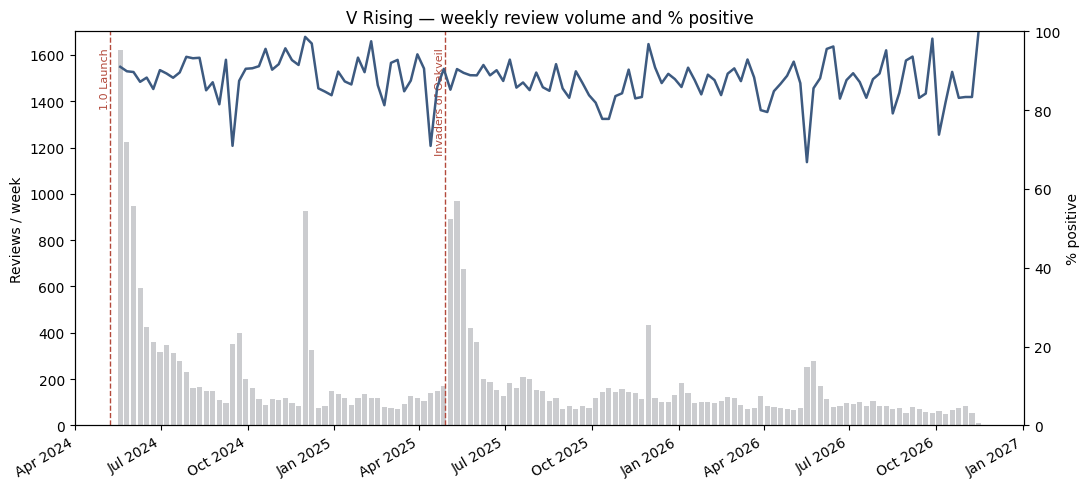

In [3]:
weekly = weekly_volume_and_positivity(df)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.bar(weekly["created_at"], weekly["num_reviews"], width=5.5, color="#6B6E76", alpha=0.35, label="Reviews / week")
ax2.plot(weekly["created_at"], weekly["pct_positive"], color="#3D5A80", linewidth=1.8, label="% positive")

for label, date_str in MAJOR_UPDATES:
    d = mdates.datestr2num(date_str)
    ax1.axvline(d, color="#B3493B", linestyle="--", linewidth=1)
    ax1.text(d, ax1.get_ylim()[1] * 0.96, label, rotation=90, fontsize=8, color="#B3493B", va="top", ha="right")

ax1.set_ylabel("Reviews / week")
ax2.set_ylabel("% positive")
ax2.set_ylim(0, 100)
ax1.set_title("V Rising — weekly review volume and % positive")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig("../images/weekly_volume_positivity.png", dpi=160)
plt.show()


**Reading this honestly:** volume spikes are the clearest, least
ambiguous signal of "something happened" around an update — a launch or a
big content drop reliably pulls in a burst of reviews. The %-positive
line is noisier and moves less than you might expect; a single bad week
of % positive on a low-volume week can look dramatic but represents very
few people.

## 2. Recurring topics in negative reviews

TF-IDF + NMF topic modeling over negative (`recommended == False`)
reviews only. For each topic: the top weighted words, and 2-3 short
representative *phrases* (not full review quotes) pulled from the
reviews that load most heavily on that topic.

In [4]:
topics = topic_model_negative_reviews(df, n_topics=6, n_top_words=8, n_examples=3)

for t in topics:
    print(f"Topic {t['topic_id']}: " + ", ".join(t["top_words"]))
    for p in t["example_phrases"]:
        print(f"    - \"{p}\"")
    print()


Topic 0: boss, bosses, gear, level, way, fight, feel, combat
    - "→ defeat every boss available at your level → unlock better gear"
    - "fight the first boss. Ok cool I want to fight the next"
    - "run on every boss or have to find exploits to edge out"

Topic 1: new, update, save, content, new content, start, access, updates
    - "save get the new content. Save on previous version? You'll be forced"
    - "New versions of the game requires a new save."
    - "to start with new saves to access the new content from the"

Topic 2: server, pvp, servers, pve, solo, people, official, single
    - "is horrendous. Some server settings aren't even there for pure PvE players"
    - "an "active PvP server" at all times - I feel like I"
    - "a Merciless mode server. Raiding players castles only happens within certain hours"

Topic 3: boring, combat, slow, grindy, repetitive, gameplay, slow boring, boring repetitive
    - "Boring. Not playing again."
    - "boring grinds with boring fight

**Caveat on topics:** NMF topics are unsupervised clusters of co-occurring
words, not ground truth categories — they need a human glance to confirm
they're coherent, and the labels above are just the model's top words,
not curated category names. Treat this as "here's where to look," not a
definitive breakdown of why people dislike the game.

## 3. Playtime at review: positive vs. negative

In [5]:
playtime_stats = playtime_by_recommendation(df)
playtime_stats


,count,median,mean,std
recommended,,,,
negative,2860,29.75,77.286766,194.921218
positive,21975,61.95,113.440347,213.312693


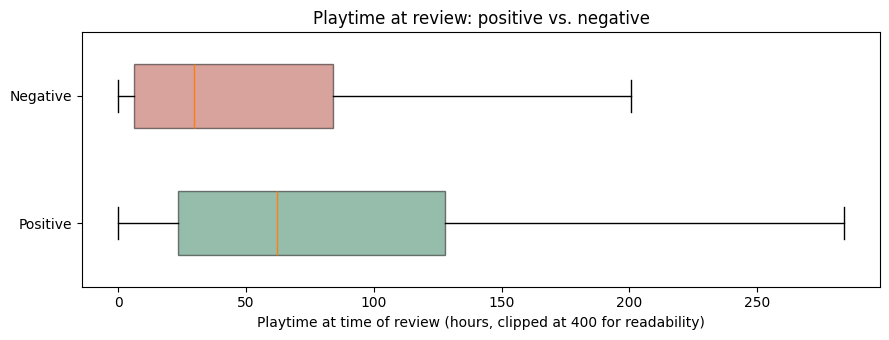

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
pos_hours = df.loc[df["recommended"], "playtime_at_review_hours"].clip(upper=400)
neg_hours = df.loc[~df["recommended"], "playtime_at_review_hours"].clip(upper=400)

bp = ax.boxplot([pos_hours, neg_hours], vert=False, tick_labels=["Positive", "Negative"],
                 patch_artist=True, widths=0.5, showfliers=False)
for patch, color in zip(bp["boxes"], ["#2E7D5B", "#B3493B"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax.set_xlabel("Playtime at time of review (hours, clipped at 400 for readability)")
ax.set_title("Playtime at review: positive vs. negative")
fig.tight_layout()
fig.savefig("../images/playtime_by_recommendation.png", dpi=160)
plt.show()


**Reading this honestly:** median playtime at review is higher for
positive reviews than negative ones. That's consistent with people who
dislike the game saying so relatively early, while people who stick
around long enough to write a glowing review have already gotten a lot
of hours out of it. It is *not* proof of why — reviews are a snapshot of
stated opinion at one point in time, not a measurement of play behavior
over time.

## Limitations (please read before citing any of this)

- **Self-selection bias.** Steam reviewers are a vocal, self-selected
  subset of players. People with mild or no opinion rarely write a
  review at all, so this is not representative of the full playerbase.
- **English-only.** Reviews in every other language are excluded
  entirely, which skews the sample toward certain regions/communities.
- **Reviews are not telemetry.** A review is a stated opinion at a single
  moment, shaped by recency, mood, and what the reviewer chooses to
  mention. It is not a measurement of actual play behavior, retention,
  or churn.
- **Numbers here are computed directly from the fetched dataset** — see
  `scripts/fetch_reviews.py` and `scripts/analysis.py` for exactly how.
  Nothing in this notebook is estimated or invented.

**What internal telemetry could add:** the things reviews structurally
can't show — exact in-session drop-off points, return cadence after a
patch, and the large silent population that never writes a review at
all but still churns or sticks around.
